# TD13: Multivariate logistic regression

Christelle Gonindard & Matthias Grenié

## 1 Introduction
In this section, we will consider simultaneously: a binary variable $Y$ (0/1) and several variables
$X_i$ $(i = 1...n)$ which can be qualitative or quantitative. We'll have the same two objectives
as in the previous session on linear regression:

1. Describe and quantify the logistic relationship between variables $X_i$ and $Y$.  
    Examples:
      - Does the effect of a drug dose depend on a factor?
      - Do medication errors depend on the organization of work within a hospital?
      - Is in-hospital mortality among acute myocardial infarction patients associated with a certain X factor?
      - Is the relative risk of adverse drug reactions associated with patient age?
2. Model and predict the values of a variable Y from the explanatory variables $X_i$ $(i = 1...n)$.  
    Examples:
      - Can the effect of a drug dose (Y) be predicted by a factor X?
      - Can medication errors (Y) be predicted by work organization X in a hospital?
      - Can in-hospital mortality among patients in the acute phase of myocardial infarction (Y) be predicted by a certain X factor?
      - Can the relative risk of adverse drug reactions (Y) be predicted by the patient's age X?
      
**Thus, $X_i$ are considered explanatory variables, while $Y$ is the variable to be explained.
the variable to be explained**.


**The goal is to model the relationship $Y = f (X_1; ...; X_n)$ by a logistic function, and to predict the
function and to predict the values of Y from $X_i$.**

Because our regression is now mediated through the $f()$ function, our model is called **generalized linear model** (GLM).

For example : 
If we wish to represent the relationship between patient age and the presence of
of heart disease:

<img src="Figures/TD8_3.jpeg" />

It appears that as age increases, so does the proportion of individuals affected by the disease.
disease increases. This relationship can be seen in the figure, which shows a clear sigmoidal
the form of a sigmoid curve. It would therefore seem “natural” to model this proportion of sufferers
as a function of age by a sigmoid curve.
Logistic regression models the probability of a patient being ill, given his or her
age:

$$ \pi(x) = \text{Probability that the patient is ill knowing that his age is x} $$
$$ \pi(x) = P[Y=1 | X=x] $$
$$ \pi(x) = \frac{e^{ax+b}}{1+e^{ax+b}}$$

## 2. Background of the study

Treatment of prostate cancer changes whether or not the cancer has spread to the lymph nodes
surrounding the prostate. To avoid an extensive investigation (opening of the abdominal cavity)
a number of variables are considered as explanatory of the variable
Y binary: Y = 0 cancer has not reached the lymphatic network, Y = 1 cancer has reached the lymphatic network. These data are taken from Collet (1991). The aim is to explain Y by the following variables:

1. Patient's age at diagnosis: `age`;
2. Serum acid phosphatase level: `acid`;
3. X-ray result, 0=negative 1=positive: `xray`;
4. Tumor size, 0=small, 1=large: `size`;
5. The pathological state of the tumor as determined by biopsy (0=medium, 1=severe): `severity`;
6. The sixth variable indicates involvement (1) or non-involvement (0) of the lymphatic system: `lymph`;
7. Logarithm of acidity level: `log.acid`.


**This type of study has two objectives:**
1. Define which explanatory variables (here: `age`, `acid`, `xray`, `size`, `severity`, and `log.acid`) have an influence on our Y variable (here `lymph`).
2. Predict an individual's risk of disease based on the results of these tests.

The data are contained in the file : `TD13_prostate.txt` in the `data/` folder.

To carry out this analysis, several steps are required:



## 3. Data analysis

### 3.1 Reading the data 

*Read and describe data*

We have 6 explanatory variables with :
- 3 quantitative variables age, log.acid and acid;
- 3 qualitative variables size, radio, and gravity (2 levels for each).

In [1]:
# Description of quantitative variables

# Description of qualitative variables


In view of these results, no outliers can be detected. In addition, the categorical variables
variables size and severity have balanced numbers, while the radio variable is more unbalanced.
The lymph variable (Y) shows that for 33 patients, the cancer did not pass into the
lymphatic network, while this was not the case for 20 other patients (balanced variable). However, it is important to note that
it's important to note that the sample size is small (only 53 patients).
In this case, it is important to limit the number of explanatory variables.
stringent in the choice of the number of explanatory variables and set correlation thresholds
thresholds.

### 3.2 Investigating correlations between $X_i$ explanatory variables

Before introducing variables into a model, it is important to check that they have little or no correlation with each other, in order to avoid redundancies in the model.

#### Correlation between qualitative explanatory variables

Let's start with the three qualitative explanatory variables radio, size and gravity.
Before introducing these three variables, we'll check whether they are correlated with each other.
correlated. As these are qualitative variables, we'll perform a $\chi ^2$ test to check for independence between the variables.
between the variables.

- H0 : ???
- H1 : ???

*Perform the tests and conclude*.

**Conclusion**:

#### Correlation between quantitative explanatory variables

Let's now consider only the quantitative variables: age, acid and log.acid.
The first step is to check for the presence of correlated variables. Since these are
quantitative variables, we use the correlation coefficient test.

- H0 : ???
- H1 : ???


*Perform the tests and conclude*.

**Conclusion**:

### 3.3 Model selection

This stage consists of two parts:

1. Build a model with all the least correlated variables selected in the previous section.
2. Checking error dispersion
3. Select variables to obtain the best possible model from our dataset 

#### Building the complete model

First, we will build the model with all the explanatory variables,
the variable Y = lymph will be predicted from the set of explanatory variables
selected above:

$$P[lymph | age + log_acid+radio + height] = \frac{ e^{a_1 \times age + a_2 \times log_acid + a_3 \times radio + a_4 \times height +b}} {1+e^{a_1 \times age + a_2 \times log_acid + a_3 \times radio + a_4 \times height +b}} $$


Logistic regression in R is performed with the glm function. Take a look at the R help file
function by opening an Inspector tab with keys `CTRL + I` and selecting the `glm()` function (you can also type `?glm` which will display the help inline after the code chunk).

*Calculate the complete model and display the results*.

In [2]:
# Build complete model

# Display result


**Interpretation**: 

#### Estimating dispersion 

An important feature to check in GLMs is whether the relationship between mean and variance respects that of the chosen model. 

For the Binomial distribution :

$$E[Y]=Np$$
    
$$Var(Y)=\phi Np(1-p)$$

The parameter φ is called the “overdispersion coefficient”.

When it is different from 1, the model does not strictly speaking follow a Binomial. 

- φ < 1 indicates underdispersion
- φ = 1 indicates that dispersion is in line with expectations 
- φ > 1 indicates overdispersion

**Overdispersion can have many causes:** extreme values

- extreme values
- non-linear relationships
- important interaction missing from the model
- important explanatory variable absent from the model 
- non-independence of observations
        
Overdispersion can often be reduced by acting on these points.

However, overdispersion of the order of 2 to 10 is quite common.

**How to estimate/detect overdispersion?**


In the case of GLMs, the residual variance is estimated from a theoretical distribution, in this case the binomial distribution. Pearson residuals are residuals standardized by the theoretical standard deviation of the predicted values.

$$residuals_i =\frac{y_i - \hat{y_i}}{S_{\hat{y_i}}}$$

$$dispersion = \frac{\sum{residuals _i ^2}}{n-k}$$

If the actual dispersion of the data is greater than that predicted by theory (1 in the case of logistic regression), then we speak of overdispersion.


**Overdispersion has consequences**.

In the case of overdispersion, the standard error of the parameters is underestimated, i.e. 
	
- the p-values
- confidence intervals, etc. 

are excessively low, which can lead to erroneous conclusions.

**How to deal with overdispersion?**

If, after trying to reduce it, overdispersion remains in this case, it is possible to use a **quasi-likelihood** approach which estimates the overdispersion and corrects standard errors, Deviance etc... 

In R code, this translates into the following script: 

In [3]:
# In the case of overdispersion, use the quasibinomial law

logistic_quasi <- glm(lymph~age + log.acid+ 
                       as.factor(radio) + as.factor(taille),family="quasibinomial",data=prostate)




ERROR: Error in eval(mf, parent.frame()): objet 'prostate' introuvable


This part will not be covered in this year's chapter. 

In [4]:
#Dispersion calculation
#dispersion(logistic_complete)
library(DHARMa)

# Calculate dispersion parameter and test for significance

Warning message:
"le package 'DHARMa' a été compilé avec la version R 4.3.2"
This is DHARMa 0.4.6. For overview type '?DHARMa'. For recent changes, type news(package = 'DHARMa')



**Interpretation:** 

#### Selecting the best possible model 

As with linear regression, we will select the “best”, i.e. in the case of prediction, the most parsimonious model. We noted that the age variable had no influence on the prediction of Y according to the Wald test. 

We're going to test the model that doesn't take the age variable into account: the model that uses the variables log.acid, radio and height: 

In [5]:
# Build new model

# Display result

In [5]:
# Calculation of dispersion

**Intepretation**:

### 3.4 Prediction based on the built model

As a reminder, the two objectives of the study were:

1. to define which explanatory variables have an influence on our Y variable: log.acid, X-ray and height
2. to predict an individual's risk of disease based on the results of these tests.

The prediction model is as follows:

$$P(Y=1| \text{log.acid, radio and size} ) =\frac{exp(a_1 log.acid + a_2 size + a_3 radio +b )}{1 + exp(a_1 log.acid + a_2 size + a_3 radio +b)}$$


$$P(Y=1| \text{log.acid, radio and size} ) =\frac{exp(2.2922 log.acid + 1.7638 size + 2.0550 radio -1.1994 )}{1 + exp(2.2922 log.acid + 1.7638 size + 2.0550 radio -1.1994)}$$

- If, for example, a patient has the following results: $(radio, height,log.acid) = (1, 1,-0.4)$, then we have :

    $$P(Y=1| \text{log.acid, radio and height }) =\frac{exp(2.2922 \times -0.4 + 1.7638 \times 1 + 2.0550 radio \times 1 -1.1994)}{1 + exp(2.2922 \times -0.4 + 1.7638 \times 1 + 2.0550 radio \times 1 -1.1994)}$$

    $$P(Y=1| \text{log.acid, radio and size }) =0.85$$


- If, for example, $(radio, size,log.acid) = (0, 0,-0.4)$, then we have :

    $$P(Y=1| \text{log.acid, radio and size }) =\frac{exp(2.2922 \times -0.4 + 1.7638 \times 0 + 2.0550 \times 0 -1.1994)}{1 + exp(2.2922 \times -0.4 + 1.7638 \times 0 + 2.0550 \times 0 -1.1994)}$$

    $$P(Y=1| \text{log.acid, radio and size} ) =0.11$$


- If, for example, $(radio, size,log.acid) = (1, 0,-0.4)$, then we have :

    $$P(Y=1| \text{ log.acid, radio and size} ) =\frac{exp(2.2922 \times -0.4 + 1.7638 \times 0 + 2.0550 \times 1 -1.1994)}{1 + exp(2.2922 \times -0.4 + 1.7638 \times 0 + 2.0550 \times 1 -1.1994)}$$

    $$P(Y=1| \text{log.acid, radio and size }) =0.49$$



Let's proceed automatically to the prediction
- Import the data file *prostate_test_patient.txt*, which contains information on the three individuals mentioned above and for whom we have performed the calculation by hand.
- Next, we'll use R's predict function, which predicts the probability of patients being ill according to the values of their explanatory variables, in this case log.acid, radio and height. This function takes as arguments your model (model_final), the form of the expected response, i.e. a probability, which corresponds to the argument type=“response”, and the new dataset containing the patients for whom you wish to make a prediction (in this case, newdata=prostate_test_patient).

In [6]:
# Read and display data from the test file


In [7]:
# Prediction for these new patients


You'll see that we've obtained the same values as those calculated by hand.

### 3.5 Model validation

1. Checking the goodness of fit of the model to the data (Hosmer Lemeshow test)

The principle of this test is as follows: check whether the disease probability curve obtained
model (theoretical curve) fits the empirical curve obtained from the sample data.
sample data. This can be expressed schematically as :
- calculating the distance between the two curves
- check that the difference is not significantly different from 0 at a certain risk $\alpha$.

To do this, the distance of $\chi ^2$ between the observed and theoretical numbers is calculated,

**Application in R: Hosmer and Lemeshow** goodness-of-fit test

Null hypothesis H0: the model fits the data correctly

Alternative hypothesis H1: model does not fit data correctly

Please note that the `hoslem.test()` function is not implemented directly in base R, but is contained in a specific package *`ResourceSelection`*.
The package  *`ResourceSelection`* is available on the CRAN website. Here's how to install it on your computer (you just have to do it once):

In [ ]:
#Installation du package
install.packages("ResourceSelection")

Cette procédure est à réaliser une seule fois, ensuite la librairie sera installée définitivement
sur votre ordinateur. En revanche, vous devrez recharger cette librairie chaque fois que vous en
avez besoin, car elle ne se chargera pas automatiquement à l’ouverture de Rstudio comme c’est
le cas pour les librairies classiques (avec l’instruction library(ResourceSelection)) .

In [ ]:
# Chargement de la librairie
library(ResourceSelection)

*Perform the Hosmer and Lemeshow test and conclude*.

In [8]:
# Calculate predictions

# display result

# test 


**Conclusion**: 

2. Test of the influence of the variables $X_i$ on Y*.


Test on the slope: Wald test** *Test on the slope: Wald test** *Test on the slope: Wald test

*Perform Wald test and conclude*.

H0 : ???

H1 : ???

*Perform Wald test and conclude*

**Comment**:

3. AIC Criterion



In [9]:
# Display AIC

**Interpretation**

According to the summary, the AIC of this new model is 56.99, whereas the AIC of the full model was 57.74, which suggests that the new model is better than the full model. 

4. Residual validation

It is important that the residuals (errors made during predictions) verify certain
conditions before accepting the model. For this purpose, studentized residuals are used, i.e.
residuals divided by their standard deviation:

$$ residuals = y_i - \pi _i$$
so
$$ residuals_{Student}=\frac{residuals}{S_{residuals}}$$

in order to have a comparable criterion whatever the dataset analyzed.

We need to check :
- normality of studentized residuals (mean 0 and standard deviation 1): shapiro test (but generally not very powerful, due to low sampling)
- residuals are homogeneous, i.e. their dispersion is homogeneous and does not depend on the values of the explanatory variable (and therefore not on the predicted values either).

These two conditions can be checked on the residuals graph. Simply project
the point cloud of studentized residuals.

* Draw the graph of residuals and comment*.

In [10]:
# Plot residuals graph

**Conclusion**:

### 3.6 Model performance evaluation

1. Principle of the ROC curve and its AUC

Logistic regression can be considered as a diagnostic model, which enables us to
to predict a person's probability of becoming ill. In this case, it is important to be able to assess the model's performance, i.e. its reliability. To do this, it is possible to calculate
indices, such as sensitivity and specificity.
The sensitivity of a test measures its ability to give a positive result when a hypothesis
is verified. It is opposed to specificity, which measures a test's ability to give a negative result when the hypothesis is not verified.
negative result when the hypothesis is not verified. These concepts are of major importance in
epidemiology, for example, notably through ROC curves.
In medicine, the sensitivity of a diagnostic test is thus its ability to detect all patients
(i.e., to have the fewest false negatives), while the specificity of the test is its ability to detect only the non
to detect only those who are not ill (i.e. to have the fewest false positives).
When a new test or examination is being developed, it is imperative to measure
its intrinsic validity (sensitivity and specificity). Using a group of individuals
whose disease status is already known, it is then possible to measure the ability of the test or examination to predict the presence of disease.


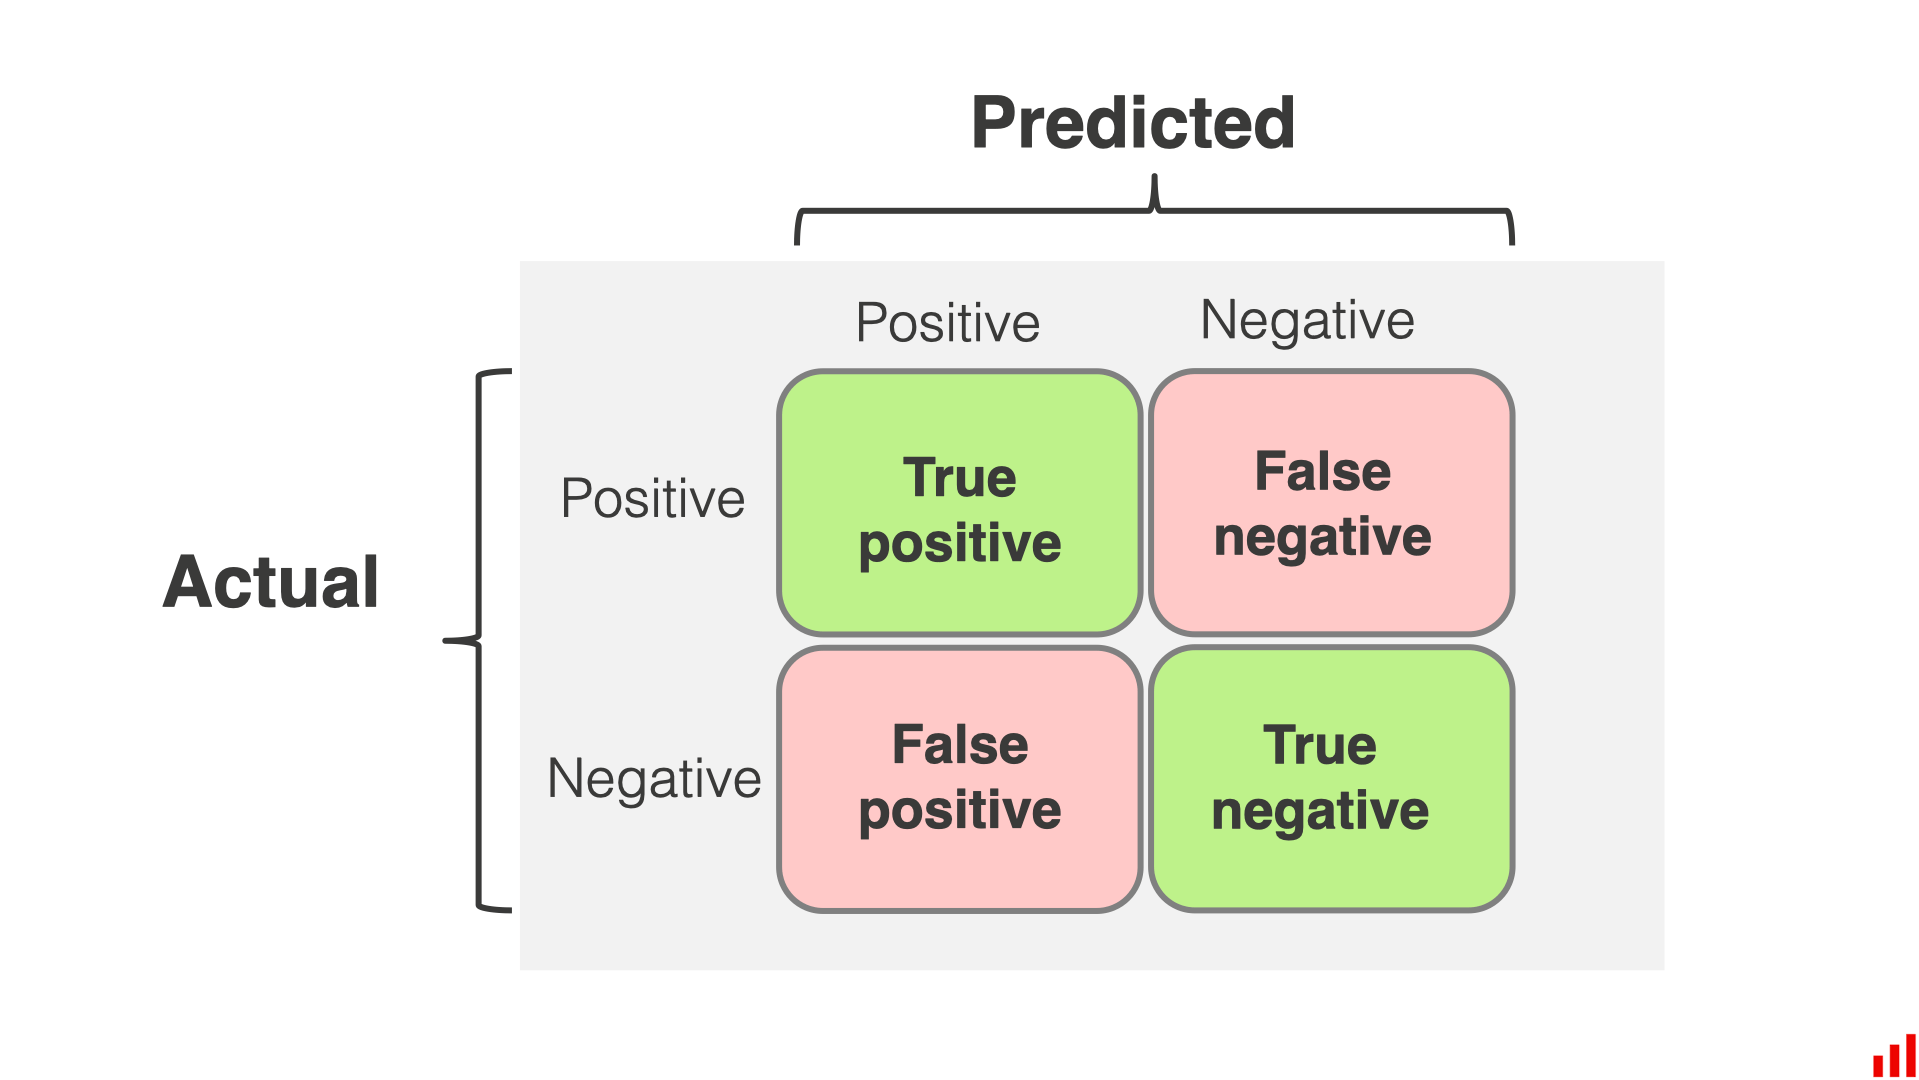

In this table, four counts are summarized:
- true positives (VP) representing the number of sick individuals with a positive test,
- false positives (FP), representing the number of non-diseased individuals with a positive test,
- false negatives (FN) representing the number of sick individuals with a negative test,
- true negatives (VN), representing the number of non-diseased individuals with a negative test.

Sensitivity, or the probability that the test will be positive if the disease is present, is measured
in patients only. It is given by :

$$ Se = \frac{VP}{VP+FN}$$


 A measure of sensitivity is always accompanied by a measure of specificity. The latter is measured in non-malignant patients only. Thus, specificity, or the probability of obtaining a negative test in non-patients, is given by :
 
$$ Sp = \frac{VN}{VN+FP}$$

The ROC curve provides a visual relationship between sensitivity and (1-specificity).
Graphically, this curve gives the true-positive rate (fraction of positives that are eectively
detected) as a function of the false positive rate (fraction of negatives that are incorrectly
detected).

Usually, we compare the probability obtained by the model with a threshold s = 0.5, to predict whether the patient is ill or not.
predict whether the patient is ill or not.
The ROC curve generalizes this idea by varying s along the entire continuum of possible values
between 0 and 1.
- At point (0, 0) the model predicts a 'negative' result every time: there are no false positives, but also no true positives.
- At point (1, 1) the model predicts a 'positive' result every time: there are no true negatives, but also no false negatives.
- A random model (e.g. one that predicts a coin toss) will draw a straight line from (0, 0) to (1, 1) (bisector).
- At (0, 1) the model has no false positives and no false negatives, and is therefore perfectly accurate, never being wrong.
- At (1, 0) the classifier has no true negatives and no true positives, and is therefore perfectly inaccurate, always getting it wrong. Simply invert its prediction to make a perfectly accurate classifier.

To determine the model's performance, the area under the ROC curve (AUC) is used.
this area is, the more the curve deviates from the line of the random model and approaches the
elbow of the ideal classifier (which goes from (0, 0) to (0, 1) to (1, 1)).

Thus, in the case of perfect discrimination, we have AUC = 1. The criteria for interpreting
of AUC are as follows:

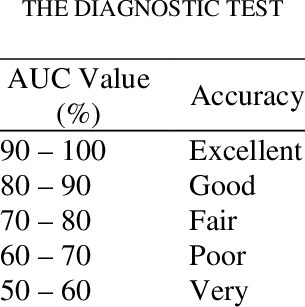

2. Drawing the ROC curve and AUC

First we need to install and load the “pROC” library, which contains the R functions
R functions for plotting the ROC curve and calculating its AUC.
Proceed in the same way as for the Resourceselection library:


In [11]:
# Installation of the package
install.packages("pROC")

Installation du package dans 'C:/Users/greniem/AppData/Local/R/win-library/4.3'
(car 'lib' n'est pas spécifié)



le package 'pROC' a été décompressé et les sommes MD5 ont été vérifiées avec succés

Les packages binaires téléchargés sont dans
	C:\Users\greniem\AppData\Local\Temp\RtmpyEquth\downloaded_packages


In [ ]:
# Load package
library(pROC)

*Plot the ROC curve, calculate its AUC and interpret*.

In [12]:
# Calculation of model predictions
# prediction function: predict(), its arguments are 
# the model you're using => model_final
# the form of the expected response (a probability) => type="response
# the dataset containing the patients for whom you wish to make a prediction
# => newdata=prostate (our starting dataset) 



# display predictions and compare with variable Y = lymph



# display the contents of variable lymph
# we can observe a correspondence between predictions 
# high probability corresponds to lymph = 1 
# low probability corresponds to lymph = 0 




#ROC curve calculation
# if red is displayed, it's not serious



#Drawing the ROC curve


# AUC value


**Interpret:**


## 4. Application exercises

### Example 1: dataset from Marion Girard's dissertation

The questions posed were as follows:

- Study the risk factors associated with drug overconsumption
- To be able to model an index that will enable the practitioner to predict for each patient the probability of overconsumption of medication.

The study was carried out via a questionnaire distributed in various pharmacies.
599 customers responded, contained in the file `TD13_drug_overconsumption.txt` in the `data/` folder.

Analyze the data set.


### Example 2: 

̈Primary biliary cirrhosis (PBC) is a rare but fatal chronic liver disease of unknown cause, with a prevalence
prevalence of around 50 cases per million in the population.

The data are in the `TD13_cirrhosis.txt` file in the `data/` folder.

Here's a description of the variables recorded from the Mayo Clinic trial in
PBC of the liver carried out between 1974 and 1984. A total of 276 patients
with PBC were enrolled in this study.

1. `id`: identifier;
2. `deceased`: 1 if deceased and 0 otherwise;
3. `age`: age in years;
4. `sex`: 0 = male, 1 = female;
5. `ascites`: presence of ascites, 0 = no, 1 = yes;
6. `albumin`: albumin in gm/dl;
7. `urine`: Urine copper, in mg/day;
8. `trigycerides`: Triglycerides, in mg/dl;
9. `histology`: Histologic stage of disease, graded 1, 2, 3, or 4.

Analyze the data set.